# code_224 · Replacement requires chronological validation and a retained prior

**Book:** section 42.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_42_GUIDE.md), [execution evidence](../CHAPTER_42_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_224).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Monitoring separates observable inputs, historical predictions, delayed outcome maturity, selection mechanisms, operational versions and authority to update. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8024;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8024


## Compare update mechanisms on separate chronological roles
 Generate eight independent200-record time blocks. Blocks0–2 are old source; a sensor-generation change at block3 replaces the first feature by its negative plus an offset0.8. The latent response law is otherwise unchanged. Blocks3–4 provide mature update labels, block5 is development, blocks6–7 are untouched final. Compare frozen old logistic, a fitted sigmoid remapping of its original log-odds (unconstrained slope can reverse ordering), full logistic refit using old plus update observations, recent-only logistic refit, and actual incremental SGD initialized with old-source training then partial_fit on update blocks. The incremental model retains its old-source scaler; refits learn their own source/update transformations. Backtest the recent-refit recipe on two earlier origins using only blocks before each target, retaining the post-change challenge. These are independent generated cohorts, not repeated rows from one asset.


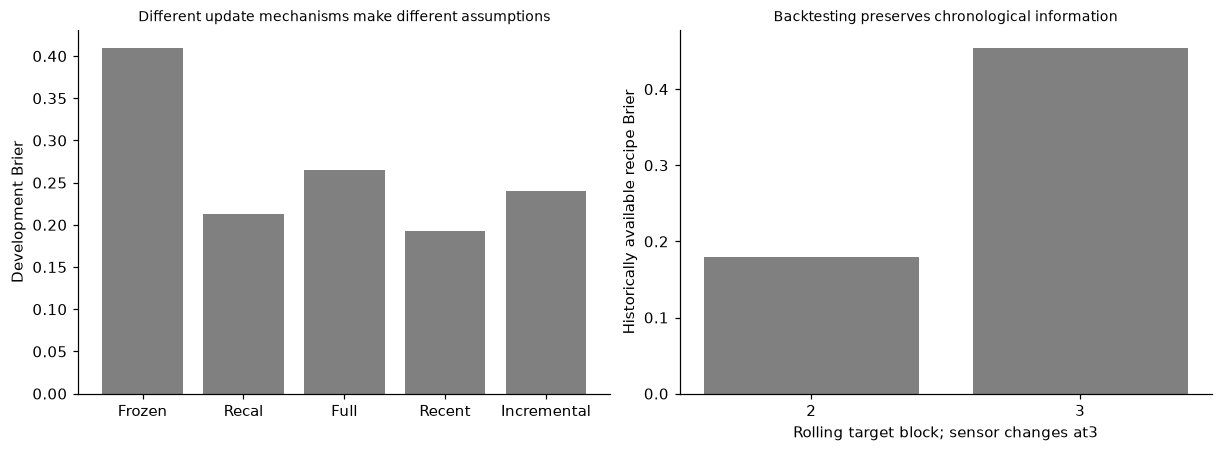

In [2]:
from sklearn.linear_model import LogisticRegression,SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
blocks=[]
for b in range(8):
    latent=rng.normal(size=(200,2));y=rng.binomial(1,expit(1.4*latent[:,0]-.5*latent[:,1]));observed=latent.copy()
    if b>=3:observed[:,0]=-observed[:,0]+.8
    blocks.append((observed,y))
source_x=np.concatenate([x for x,y in blocks[:3]]);source_y=np.concatenate([y for x,y in blocks[:3]]);update_x=np.concatenate([x for x,y in blocks[3:5]]);update_y=np.concatenate([y for x,y in blocks[3:5]]);dx,dy=blocks[5];fx=np.concatenate([x for x,y in blocks[6:]]);fy=np.concatenate([y for x,y in blocks[6:]]);old=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(source_x,source_y);recal=LogisticRegression(C=1).fit(old.decision_function(update_x)[:,None],update_y);full=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(np.r_[source_x,update_x],np.r_[source_y,update_y]);recent=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(update_x,update_y);fixed=StandardScaler().fit(source_x);incremental=SGDClassifier(loss='log_loss',alpha=.01,learning_rate='constant',eta0=.01,random_state=SEED)
for _ in range(10):incremental.partial_fit(fixed.transform(source_x),source_y,classes=np.array([0,1]))
for b in [3,4]:incremental.partial_fit(fixed.transform(blocks[b][0]),blocks[b][1])
predictors={'Frozen':lambda x:old.predict_proba(x)[:,1],'Recalibration':lambda x:recal.predict_proba(old.decision_function(x)[:,None])[:,1],'Full refit':lambda x:full.predict_proba(x)[:,1],'Recent refit':lambda x:recent.predict_proba(x)[:,1],'Incremental':lambda x:incremental.predict_proba(fixed.transform(x))[:,1]};dev={name:float(np.mean((fn(dx)-dy)**2)) for name,fn in predictors.items()};backtests=[]
for origin in [2,3]:
    tx=np.concatenate([x for x,y in blocks[max(0,origin-2):origin]]);ty=np.concatenate([y for x,y in blocks[max(0,origin-2):origin]]);m=make_pipeline(StandardScaler(),LogisticRegression(C=1)).fit(tx,ty);backtests.append({'target_block':origin,'training_blocks':list(range(max(0,origin-2),origin)),'Brier':float(np.mean((m.predict_proba(blocks[origin][0])[:,1]-blocks[origin][1])**2))})
assert len(fy)==400 and all(max(r['training_blocks'])<r['target_block'] for r in backtests);RESULTS.update(old_source_blocks=[0,1,2],mature_update_blocks=[3,4],development_block=5,untouched_final_blocks=[6,7],source_rows=600,update_rows=400,development_rows=200,final_rows=400,development_Brier=dev,rolling_origin_checks=backtests,incremental_scaler_fitted_on_old_source_only=True,recalibration_logit_slope=float(recal.coef_[0,0]));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(range(5),list(dev.values()),color='.5');axes[0].set(xticks=range(5),xticklabels=['Frozen','Recal','Full','Recent','Incremental'],ylabel='Development Brier',title='Different update mechanisms make different assumptions');axes[1].bar([str(r['target_block']) for r in backtests],[r['Brier'] for r in backtests],color='.5');axes[1].set(xlabel='Rolling target block; sensor changes at3',ylabel='Historically available recipe Brier',title='Backtesting preserves chronological information');plt.show()


## Freeze the gate before evaluating the future, then rehearse rollback
 Rank the four update candidates on development Brier only. Replacement requires improvement over frozen by0.01 and development Brier below0.25; otherwise retain old. A fixed schedule would investigate/update at every block boundary, while an evidence trigger opens investigation only when the old model's mature block loss exceeds0.30. Neither trigger bypasses validation. Evaluate all frozen candidates on final blocks for reporting without changing the choice. Retain the prior package object, copy the development-selected route, then simulate an incident that restores prior predictions exactly. VisualB labels source/update/development/final roles, gate, release fixture and recoverable prior. This is a local scenario, not a real approval or automatic field release.


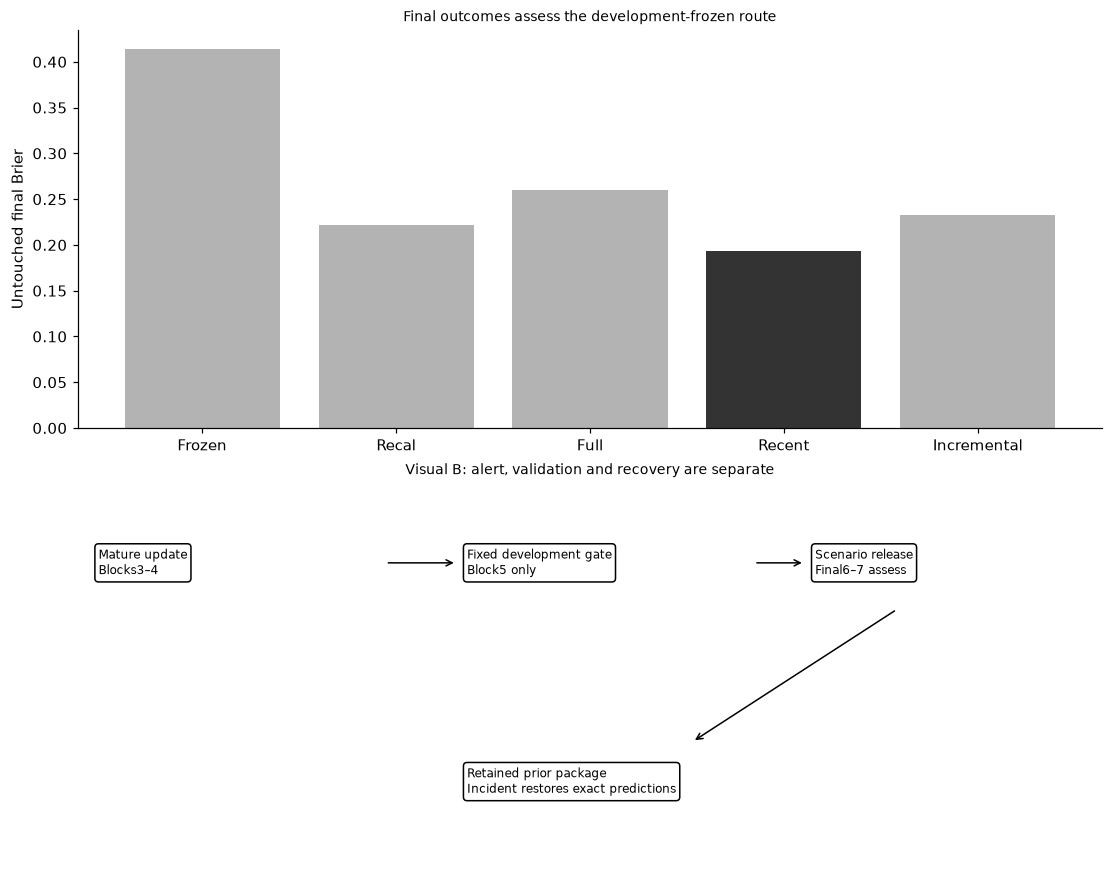

In [3]:
candidates=[name for name in predictors if name!='Frozen'];chosen=min(candidates,key=lambda name:dev[name]);accepted=bool(dev[chosen]<=dev['Frozen']-.01 and dev[chosen]<.25);released=chosen if accepted else 'Frozen';final={name:float(np.mean((fn(fx)-fy)**2)) for name,fn in predictors.items()};trigger_loss=[float(np.mean((predictors['Frozen'](blocks[b][0])-blocks[b][1])**2)) for b in [3,4]];triggered=[b for b,loss in zip([3,4],trigger_loss) if loss>.30];prior=predictors['Frozen'](fx).copy();release_predictions=predictors[released](fx);rollback=predictors['Frozen'](fx);assert np.array_equal(prior,rollback);assert chosen in candidates and released==(chosen if accepted else 'Frozen');RESULTS.update(development_selected_candidate=chosen,development_gate_passed=accepted,released_scenario_route=released,final_Brier=final,scheduled_investigation_blocks=[3,4],mature_evidence_trigger_blocks=triggered,trigger_old_Brier=trigger_loss,gate_uses_final_outcomes=False,rollback_prior_predictions_exact=True,real_human_approval_executed=False);fig,axes=plt.subplots(2,1,figsize=(10,8));axes[0].bar(range(5),list(final.values()),color=['.2' if name==released else '.7' for name in final]);axes[0].set(xticks=range(5),xticklabels=['Frozen','Recal','Full','Recent','Incremental'],ylabel='Untouched final Brier',title='Final outcomes assess the development-frozen route');axes[1].axis('off');axes[1].set(xlim=(0,10),ylim=(0,6));labels=[(.2,4.8,'Mature update\nBlocks3–4'),(3.8,4.8,'Fixed development gate\nBlock5 only'),(7.2,4.8,'Scenario release\nFinal6–7 assess'),(3.8,1.5,'Retained prior package\nIncident restores exact predictions')]
for x,y,label in labels:axes[1].text(x,y,label,va='center',fontsize=8,bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
for a,b in [((3,4.8),(3.7,4.8)),((6.6,4.8),(7.1,4.8)),((8,4.1),(6,2.1))]:axes[1].annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->'})
axes[1].set_title('Visual B: alert, validation and recovery are separate');plt.show()


In [4]:
summary={'example_id':'code_224','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual old frozen Platt recalibration full refit recent refit and incremental SGD after sensor-generation change', 'mature chronological update development and untouched final cohorts with rolling-origin checks', 'scheduled versus evidence-triggered update decisions with fixed development acceptance criteria', 'versioned candidate gate and actual retained-prior rollback visual'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual old frozen Platt recalibration full refit recent refit and incremental SGD after sensor-generation change", "mature chronological update development and untouched final cohorts with rolling-origin checks", "scheduled versus evidence-triggered update decisions with fixed development acceptance criteria", "versioned candidate gate and actual retained-prior rollback visual"], "elapsed_seconds": 0.291, "example_id": "code_224", "hardware": "Darwin arm64 CPU", "results": {"development_Brier": {"Frozen": 0.40997707049005505, "Full refit": 0.2655020065119007, "Incremental": 0.2400404534475043, "Recalibration": 0.21331550015196002, "Recent refit": 0.1922055329761992}, "development_block": 5, "development_gate_passed": true, "development_rows": 200, "development_selected_candidate": "Recent refit", "final_Brier": {"Frozen": 0.4137136818994276, "Full refit": 0.2604157071421511, "Incremental": 0.23264944669028118, "Recalibration": 0.222103